In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Employee_Attrition_Analysis.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [17]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   Busin

In [18]:
df = df.drop_duplicates()
df = df.dropna()

print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

Cleaned Dataset Shape: (1470, 35)
Missing Values: 0


In [19]:
print("Employee Attrition Count:")
print(df["Attrition"].value_counts())

attrition_rate = (df["Attrition"].eq("Yes").mean()) * 100

print(f"\nAttrition Rate: {attrition_rate:.2f}%")

Employee Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Rate: 16.12%


In [20]:
department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

print(department_attrition)

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92


In [21]:
age_attrition = df.groupby("Attrition")["Age"].mean()

print(age_attrition)

Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64


In [22]:
income_attrition = df.groupby("Attrition")["MonthlyIncome"].mean()

print(income_attrition)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


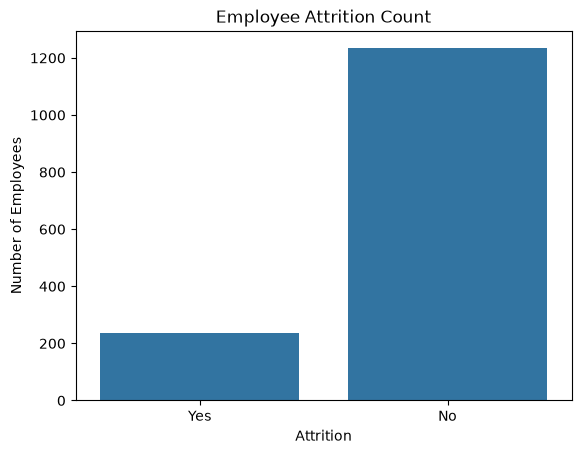

In [23]:
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Count")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()


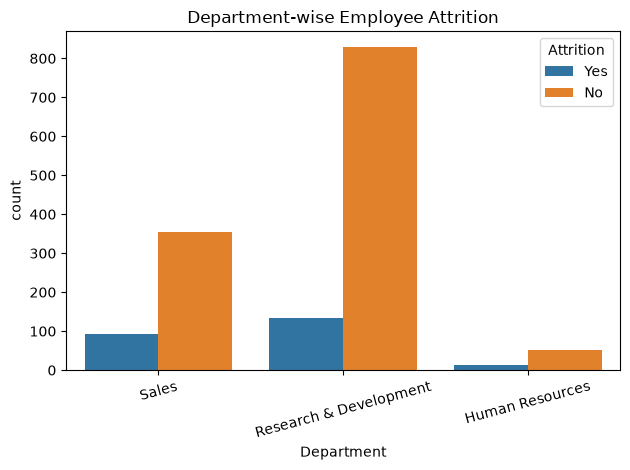

In [24]:
sns.countplot(data=df, x="Department", hue="Attrition")
plt.title("Department-wise Employee Attrition")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

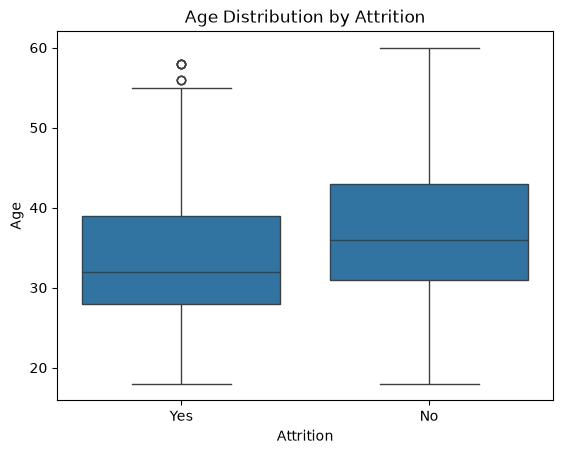

In [25]:
sns.boxplot(data=df, x="Attrition", y="Age")
plt.title("Age Distribution by Attrition")
plt.show()

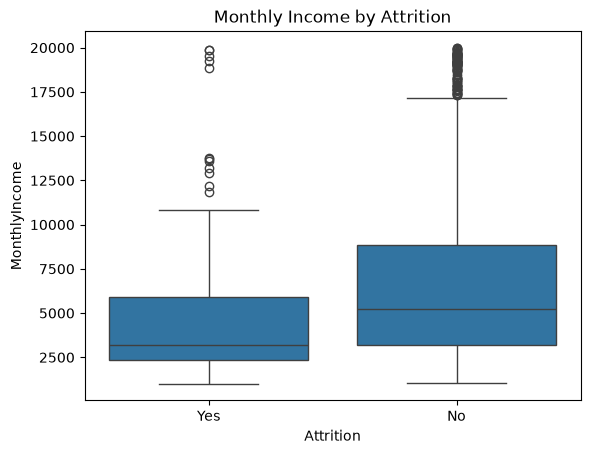

In [26]:
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income by Attrition")
plt.show()

In [27]:
print("EMPLOYEE ATTRITION ANALYSIS - SUMMARY")
print("-" * 40)

print(f"Total Employees: {len(df)}")
print(f"Employees Left: {(df['Attrition'] == 'Yes').sum()}")
print(f"Employees Stayed: {(df['Attrition'] == 'No').sum()}")
print(f"Attrition Rate: {(df['Attrition'] == 'Yes').mean() * 100:.2f}%")

print("\nDepartment-wise Attrition:")
print(df[df["Attrition"] == "Yes"]["Department"].value_counts())

EMPLOYEE ATTRITION ANALYSIS - SUMMARY
----------------------------------------
Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12%

Department-wise Attrition:
Department
Research & Development    133
Sales                      92
Human Resources            12
Name: count, dtype: int64


In [28]:
df.to_csv("cleaned_employee_attrition.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [29]:
print("PROJECT: Employee Attrition Analysis")
print("-" * 40)
print("Total Employees:", len(df))
print("Employees Left:", (df["Attrition"] == "Yes").sum())
print("Employees Stayed:", (df["Attrition"] == "No").sum())
print(f"Attrition Rate: {(df['Attrition'] == 'Yes').mean() * 100:.2f}%")
print("\nDepartment-wise Attrition:")
print(df[df["Attrition"] == "Yes"]["Department"].value_counts())

PROJECT: Employee Attrition Analysis
----------------------------------------
Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12%

Department-wise Attrition:
Department
Research & Development    133
Sales                      92
Human Resources            12
Name: count, dtype: int64
